# 5장 3강: 배깅 vs 부스팅 선택과 모델 해석(SHAP)

## 실습 목표

이번 실습에서는 **Ames Housing** 데이터를 이용하여 배깅과 부스팅을 비교하고, SHAP으로 앙상블 모델의 예측 근거를 해석합니다.

- Random Forest와 XGBoost의 구조적 차이를 비교합니다.
- 성능과 학습 시간을 확인하여 상황에 맞는 모델 선택 기준을 정리합니다.
- Feature Importance의 특징과 한계를 확인합니다.
- TreeSHAP을 이용해 모델 전체의 **전역 해석**을 수행합니다.
- 특정 주택 한 건의 예측을 **지역 해석**합니다.
- SHAP 값의 부호를 이용하여 각 특성이 예측값을 올렸는지 내렸는지 설명합니다.

> 이 실습에서는 5장 3강 교안에 나온 배깅/부스팅 비교, Feature Importance, SHAP 전역·지역 해석 내용만 사용합니다.

## 실습 환경 / 데이터

- Python
- pandas
- matplotlib
- scikit-learn
- xgboost
- shap
- 데이터: `Ames_Housing.csv`

### 분석 목표

주택 특성을 이용하여 `SalePrice`를 예측하는 회귀 문제입니다.

### 사용할 특성

- `OverallQual`
- `GrLivArea`
- `GarageCars`
- `GarageArea`
- `TotalBsmtSF`
- `1stFlrSF`
- `2ndFlrSF`
- `FullBath`
- `TotRmsAbvGrd`
- `YearBuilt`
- `YearRemodAdd`
- `Fireplaces`

예측 대상은 `SalePrice`입니다.

## 실습 준비

1. Ames Housing 데이터를 불러옵니다.
2. 사용할 숫자형 특성과 `SalePrice`를 선택합니다.
3. Train / Test 데이터로 분리합니다.
4. Random Forest와 XGBoost를 같은 데이터에서 비교합니다.
5. SHAP은 XGBoost 모델을 대상으로 확인합니다.

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from xgboost import XGBRegressor

house = pd.read_csv("Ames_Housing.csv")

features = ["OverallQual", "GrLivArea", "GarageCars", "GarageArea",
    "TotalBsmtSF", "1stFlrSF", "2ndFlrSF", "FullBath",
    "TotRmsAbvGrd", "YearBuilt", "YearRemodAdd", "Fireplaces"]

X = house[features]
y = house["SalePrice"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,
    random_state=42)

print("Train 크기:", X_train.shape)
print("Test 크기:", X_test.shape)

Train 크기: (1168, 12)
Test 크기: (292, 12)


c:\practical_machine_learning_assignment_seungwon\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


---

# 필수 1. 배깅과 부스팅 비교 및 선택

## 문제 1. Random Forest와 XGBoost를 비교하세요.

### 요구사항

다음 두 모델을 사용합니다.

```python
RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

XGBRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)
```

각 모델에 대해 다음을 확인합니다.

1. Train 데이터로 학습합니다.
2. 학습 시간을 측정합니다.
3. Test 데이터를 예측합니다.
4. Test RMSE를 계산합니다.
5. Test R²를 계산합니다.
6. 결과를 하나의 DataFrame으로 정리합니다.

### 확인 포인트

- Random Forest가 배깅 계열이라는 점을 이해했는가?
- XGBoost가 부스팅 계열이라는 점을 이해했는가?
- 성능뿐 아니라 학습 시간도 함께 확인했는가?

In [2]:
# TODO
# Random Forest와 XGBoost의 Test RMSE, Test R², 학습 시간을 비교하세요.

### Q1. Random Forest와 XGBoost의 학습 방식은 어떻게 다른가요?

### Q2. 다음 상황에서 어떤 방식을 우선 후보로 생각할 수 있는지 작성하세요.

---

# 필수 2. Feature Importance와 SHAP 전역 해석

## 문제 1. XGBoost의 Feature Importance를 확인하세요.

### 요구사항

1. 필수 1에서 학습한 XGBoost 모델을 사용합니다.
2. `feature_importances_`를 이용합니다.
3. 특성명과 중요도를 DataFrame으로 만듭니다.
4. 중요도가 높은 순서대로 정렬합니다.
5. 막대그래프로 표시합니다.

### 확인 포인트

- 어떤 특성이 모델 전체에서 중요하게 사용되었는지 확인했는가?
- 중요도의 크기는 알 수 있지만 방향은 알 수 없다는 점을 이해했는가?

In [3]:
# TODO
# XGBoost의 Feature Importance를 표와 그래프로 확인하세요.

### Q3. Feature Importance만으로는 알기 어려운 정보는 무엇인가요?

## 문제 2. TreeSHAP으로 전역 중요도를 확인하세요.

### 요구사항

1. `shap.TreeExplainer()`에 XGBoost 모델을 전달합니다.
2. Test 데이터의 SHAP 값을 계산합니다.
3. `shap.plots.bar()`로 전역 중요도를 확인합니다.
4. SHAP 절댓값의 평균도 계산하여 특성별 중요도를 DataFrame으로 정리합니다.
5. 상위 특성을 확인합니다.

### 확인 포인트

- SHAP은 각 특성이 예측값에 기여한 정도를 계산한다는 점을 이해했는가?
- 전역 SHAP에서는 여러 샘플의 기여도 크기를 종합해 전체 중요도를 볼 수 있는가?

In [4]:
# TODO
# TreeSHAP을 이용해 XGBoost 모델의 전역 SHAP 중요도를 확인하세요.


### Q4. Feature Importance와 SHAP의 가장 큰 차이는 무엇인가요?

---
# 과제 1. 모델 비교·SHAP 해석과 특성 선택 전후 검증

## 배경
주택 가격 예측 모델을 성능과 학습 시간으로 비교하고, SHAP으로 예측 근거를 설명합니다. 이어서 중요한 특성을 선택했을 때 검증 성능이 어떻게 달라지는지 확인합니다.

> 필수 1·2는 연습용입니다. 아래 과제의 비교표·해석·코드를 제출하세요. 준비 단계의 `X_train`, `y_train`을 사용하되 과제용 모델을 새로 학습합니다. Test 결과로 모델이나 특성을 선택하지 않도록, Train 안에서 Validation을 분리합니다. 개별 주택 해석 대상도 Validation의 첫 번째 주택으로 맞춥니다.

## 요구사항

### 1. 같은 조건에서 모델 비교
1. `X_train`, `y_train`을 Train_sub / Validation으로 나누세요(`test_size=0.2`, `random_state=42`). 결측값이 있으면 Train_sub에서 구한 중앙값으로 두 데이터를 채우세요.
2. Random Forest(`n_estimators=200`)와 XGBoost(`n_estimators=200`, `learning_rate=0.05`, `max_depth=3`)를 같은 Train_sub에서 학습하세요. 두 모델 모두 `random_state=42`, `n_jobs=1`로 설정하세요.
3. 각 모델의 **fit에 걸린 시간**, Train_sub RMSE, Validation RMSE와 R²를 `model_comparison`으로 정리하세요. 시간은 같은 환경에서 측정하며, 한 번의 측정만으로 일반적인 속도 우열을 단정하지 마세요.
4. 예측 오차, 학습 시간, Train/Validation 오차 차이와 운영 목적을 근거로 우선 후보를 선택하세요. 모델 선택 결과와 관계없이 다음 해석은 XGBoost로 수행합니다.

### 2. Feature Importance와 SHAP 전역·지역 해석
5. 과제용 XGBoost의 `feature_importances_`와 **Train_sub의 평균 절댓값 SHAP**을 각각 순위로 정리하여 `importance_comparison`으로 비교하세요. 전역 SHAP 막대그래프도 제출하세요.
6. Validation의 첫 번째 주택의 실제 가격·예측가격을 확인하고 SHAP waterfall plot을 그리세요.
7. 해당 주택의 절댓값 SHAP 상위 5개 특성·특성값·SHAP 값을 `local_top5`로 정리하세요. 양수·음수의 의미를 설명하고 기준값 + 모든 SHAP 값의 합이 예측값과 거의 같은지 확인하세요.
8. 두 전역 중요도 산출 원리와 한계를 비교하고, 전역 순위와 개별 주택의 기여도가 다른 이유를 설명하세요.

### 3. 중요도에 근거한 특성 선택 및 검증
9. Train_sub의 평균 절댓값 SHAP이 높은 **상위 6개 특성**을 선택하세요. 특성 선택은 이번 과제의 특성 개선 시도입니다. 개수는 비교 결과를 보기 전에 6개로 고정합니다.
10. 선택한 특성만 사용하여 동일한 XGBoost 설정으로 다시 학습하세요. 기존 모델과 동일한 Train_sub / Validation 행을 사용하고, 특성 이외의 조건은 유지하세요.
11. 전체 특성 모델과 선택 특성 모델의 특성 수·학습 시간·Train RMSE·Validation RMSE·Validation R²를 `feature_comparison`으로 비교하세요. `기존 Validation RMSE - 선택 후 Validation RMSE`와 기존 대비 개선율(%)을 계산하세요.
12. 개선 여부와 채택 여부를 수치로 설명하세요. 성능이 나빠져도 원인 가능성과 한계를 타당하게 설명하면 됩니다. 검증 결과를 반복 확인하며 특성을 바꾸지 말고, 최종 일반화 성능 확인에는 별도 Test 평가가 필요함을 밝히세요.

## 해석 질문

### Q5. 전역 SHAP에서 가장 중요한 특성이 특정 주택에서도 반드시 가장 큰 영향을 주나요?
### Q6. SHAP 값이 양수/음수라는 것은 각각 무엇을 의미하나요?
### Q7. 두 모델 중 무엇을 우선 후보로 선택했나요? 성능·학습 시간·과적합 징후와 주택 가격 예측 업무를 연결하여 설명하세요.
### Q8. Feature Importance와 평균 절댓값 SHAP의 계산 원리와 한계는 무엇이며, 실제 상위 특성 순위는 어떻게 다른가요?
### Q9. 상위 6개 특성은 무엇이며, 선택 전후 RMSE 차이와 개선율은 얼마인가요? 이 시도를 채택할지와 판단의 한계를 설명하세요.

## 제출물 / 확인 포인트
- `model_comparison`, `importance_comparison`, 전역 SHAP 그래프
- 개별 주택의 실제값·예측값·waterfall plot·`local_top5`·SHAP 합 검증
- 선택한 6개 특성, `feature_comparison`, RMSE 차이와 개선율
- 계산 코드와 Q5~Q9 답변
- 동일한 검증 조건 유지, SHAP의 방향·전역/지역 구분, 관측한 개선 여부와 해석의 한계

In [5]:
# TODO 1: 같은 Train_sub / Validation으로 두 모델의 성능과 fit 시간을 비교하세요.

X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42)

# 결측값은 Train_sub의 중앙값으로 채움 
med = X_tr.median()
X_tr = X_tr.fillna(med)
X_val = X_val.fillna(med)

# RMSE 계산 함수
def get_rmse(y_true, pred):
    return mean_squared_error(y_true, pred) ** 0.5

# 비교할 두 모델
task_models = {
    "RandomForest": RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=1),
    "XGBoost": XGBRegressor(n_estimators=200, learning_rate=0.05, max_depth=3,
                            random_state=42, n_jobs=1)}

rows = []
for name, model in task_models.items():
    # fit에 걸린 시간만 측정
    start = time.time()
    model.fit(X_tr, y_tr)
    elapsed = time.time() - start

    # Train_sub / Validation 예측
    pred_tr = model.predict(X_tr)
    pred_val = model.predict(X_val)

    rows.append({
        "model": name,
        "fit_seconds": elapsed,
        "train_rmse": get_rmse(y_tr, pred_tr),
        "val_rmse": get_rmse(y_val, pred_val),
        "val_r2": r2_score(y_val, pred_val)})

# 결과표 + Train/Validation 오차 차이
model_comparison = pd.DataFrame(rows)
model_comparison["rmse_gap"] = model_comparison["val_rmse"] - model_comparison["train_rmse"]
display(model_comparison)

# 이후 해석에 사용할 XGBoost 모델
xgb_task = task_models["XGBoost"]

,model,fit_seconds,train_rmse,val_rmse,val_r2,rmse_gap
0,RandomForest,0.844756,12367.658293,29317.762180,0.867024,16950.103887
1,XGBoost,1.176697,19116.641546,27436.846466,0.883539,8320.204920


,feature,importance,mean_abs_shap,importance_rank,shap_rank
0,OverallQual,0.427782,25416.365234,1.0,1.0
1,GrLivArea,0.078942,13777.564453,3.0,2.0
4,TotalBsmtSF,0.045537,9604.813477,6.0,3.0
10,YearRemodAdd,0.025395,7255.513184,9.0,4.0
11,Fireplaces,0.045971,6242.651367,5.0,5.0
9,YearBuilt,0.034376,6187.059570,7.0,6.0
2,GarageCars,0.205156,3490.014404,2.0,7.0
5,1stFlrSF,0.050895,3446.147461,4.0,8.0
3,GarageArea,0.016150,2788.530762,11.0,9.0
6,2ndFlrSF,0.033605,2005.598633,8.0,10.0


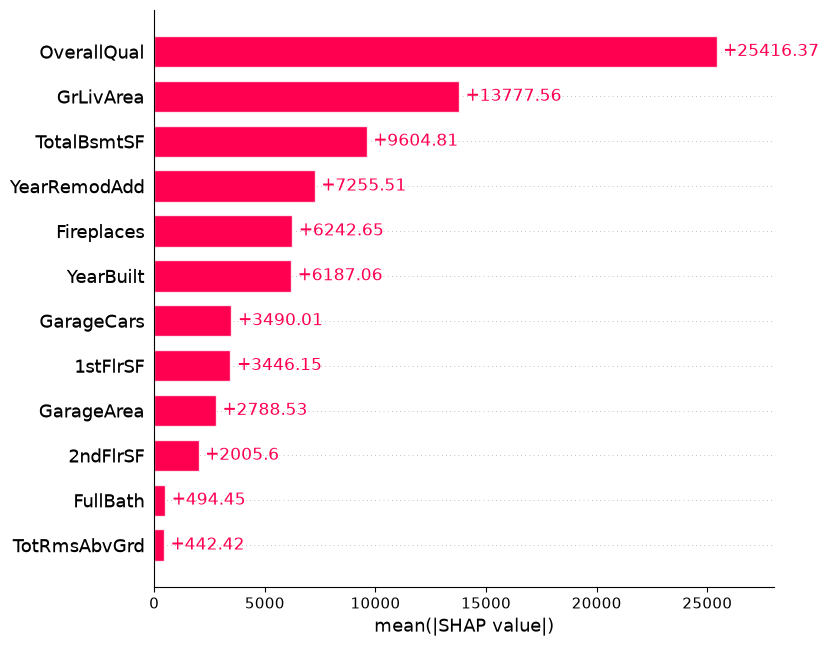

실제 가격: 140,000 / 예측 가격: 149,904


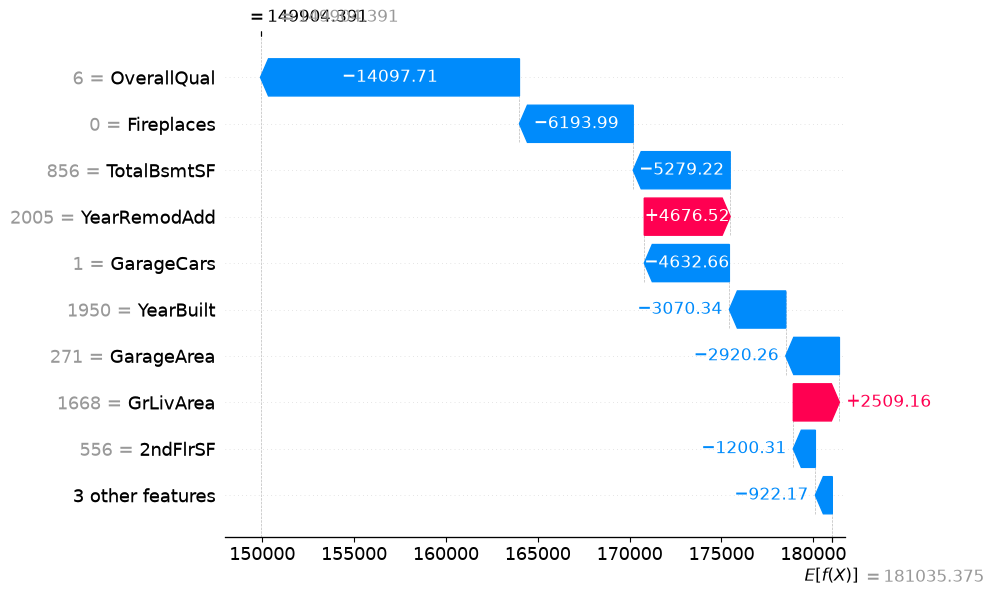

,feature,feature_value,shap_value,abs_shap
0,OverallQual,6,-14097.710938,14097.710938
11,Fireplaces,0,-6193.989258,6193.989258
4,TotalBsmtSF,856,-5279.219727,5279.219727
10,YearRemodAdd,2005,4676.523438,4676.523438
2,GarageCars,1,-4632.663086,4632.663086


기준값 + SHAP 합: 149,904.39 / 예측값: 149,904.42
거의 같은가? True


In [6]:
# TODO 2: 과제용 XGBoost의 Feature Importance, Train_sub 전역 SHAP, Validation 첫 주택의 지역 SHAP을 확인하세요.

# SHAP 계산: 전역은 Train_sub, 지역은 Validation 사용
explainer = shap.TreeExplainer(xgb_task)
shap_train = explainer(X_tr)
shap_val = explainer(X_val)

# feature_importances_ vs 평균 |SHAP| 순위 비교표
importance_comparison = pd.DataFrame({
    "feature": X_tr.columns,
    "importance": xgb_task.feature_importances_,
    "mean_abs_shap": np.abs(shap_train.values).mean(axis=0)})
importance_comparison["importance_rank"] = importance_comparison["importance"].rank(ascending=False)
importance_comparison["shap_rank"] = importance_comparison["mean_abs_shap"].rank(ascending=False)
importance_comparison = importance_comparison.sort_values("shap_rank")
display(importance_comparison)

# 전역 SHAP 막대그래프
shap.plots.bar(shap_train, max_display=12)

# Validation 첫 주택의 실제가 / 예측가
actual = y_val.iloc[0]
pred = xgb_task.predict(X_val.iloc[[0]])[0]
print(f"실제 가격: {actual:,.0f} / 예측 가격: {pred:,.0f}")

# 지역 SHAP waterfall plot
shap.plots.waterfall(shap_val[0])

# 절댓값 SHAP 상위 5개 (양수: 가격을 올림 / 음수: 가격을 내림)
local_df = pd.DataFrame({
    "feature": X_val.columns,
    "feature_value": X_val.iloc[0].values,
    "shap_value": shap_val[0].values})
local_df["abs_shap"] = local_df["shap_value"].abs()
local_top5 = local_df.sort_values("abs_shap", ascending=False).head(5)
display(local_top5)

# 가산성 확인: 기준값 + SHAP 합 ≈ 모델 예측값
total = shap_val[0].base_values + shap_val[0].values.sum()
print(f"기준값 + SHAP 합: {total:,.2f} / 예측값: {pred:,.2f}")
print("거의 같은가?", np.isclose(total, pred, atol=1))

In [7]:
# TODO 3: Train_sub SHAP 상위 6개 특성으로 재학습하고 동일 Validation에서 전후 성능을 비교하세요.

# Train_sub 평균 |SHAP| 상위 6개 특성 선택 (개수 6개로 고정)
top6 = importance_comparison.sort_values("mean_abs_shap", ascending=False)["feature"].head(6).tolist()
print("선택 특성:", top6)

xgb_sel = XGBRegressor(n_estimators=200, learning_rate=0.05, max_depth=3,
                       random_state=42, n_jobs=1)
start = time.time()
xgb_sel.fit(X_tr[top6], y_tr)
sel_time = time.time() - start

full_time = model_comparison.loc[1, "fit_seconds"]

# 전체 특성 vs 선택 특성 비교표
feature_comparison = pd.DataFrame({
    "model": ["전체 특성", "선택 특성(6)"],
    "n_features": [X_tr.shape[1], len(top6)],
    "fit_seconds": [full_time, sel_time],
    "train_rmse": [get_rmse(y_tr, xgb_task.predict(X_tr)),
                   get_rmse(y_tr, xgb_sel.predict(X_tr[top6]))],
    "val_rmse": [get_rmse(y_val, xgb_task.predict(X_val)),
                 get_rmse(y_val, xgb_sel.predict(X_val[top6]))],
    "val_r2": [r2_score(y_val, xgb_task.predict(X_val)),
               r2_score(y_val, xgb_sel.predict(X_val[top6]))]})
display(feature_comparison)

# 기존 Validation RMSE - 선택 후 Validation RMSE (양수면 개선), 개선율(%)
diff = feature_comparison.loc[0, "val_rmse"] - feature_comparison.loc[1, "val_rmse"]
pct = diff / feature_comparison.loc[0, "val_rmse"] * 100
print(f"RMSE 차이(기존-선택후): {diff:,.2f} / 개선율: {pct:.2f}%")
print("개선됨" if diff > 0 else "개선되지 않음", "→ 최종 일반화 성능은 별도 Test 평가가 필요함")

선택 특성: ['OverallQual', 'GrLivArea', 'TotalBsmtSF', 'YearRemodAdd', 'Fireplaces', 'YearBuilt']


,model,n_features,fit_seconds,train_rmse,val_rmse,val_r2
0,전체 특성,12,1.176697,19116.641546,27436.846466,0.883539
1,선택 특성(6),6,0.046515,20282.480322,30029.857143,0.860486


RMSE 차이(기존-선택후): -2,593.01 / 개선율: -9.45%
개선되지 않음 → 최종 일반화 성능은 별도 Test 평가가 필요함


## Q5~Q9 답변

- Q5: 아니다. 전역 SHAP은 전체 주택의 평균 영향이고, 개별 주택에서는 그 주택의 특성값이 기준(평균)에서 얼마나 벗어났는지에 따라 기여 순위가 달라진다.
- Q6: 양수는 해당 특성값이 예측가를 기준값(평균 예측가)보다 올리는 방향이고 음수는 내리는 방향으로 작용했다는 뜻이다.
- Q7: XGBoost를 선택했다. Validation RMSE(27,437 vs 29,318)와 R²(0.884 vs 0.867)가 더 좋고, Train–Val 오차 차이(8,320 vs 16,950)가 작아 RandomForest의 과적합이 뚜렸하다. 학습 시간(0.076초 vs 0.974초)은 1회 측정이라 보조 근거로만 봤고 가격 예측은 오차가 곧 금전 손실이라 정확도와 일반화를 우선시 하였다.
- Q8: feature_importances_는 분할 시 손실 감소 기반이라 방향을 모르고 상관 특성 간 배분이 불안정하며 평균 |SHAP|은 예측별 기여의 평균이라 방향 해석이 가능하지만 상관 특성 간 분배가 모호하고 계산 비용이 든다. 둘 다 OverallQual이 1위지만 GarageCars는 2위 vs 7위, YearRemodAdd는 9위 vs 4위로 크게 달랐다.
- Q9: 상위 6개는 OverallQual, GrLivArea, TotalBsmtSF, YearRemodAdd, Fireplaces, YearBuilt이다. Validation RMSE가 27,437에서 30,030으로 −2,593(−9.45%) 악화되어 채택하지 않고 전체 12개 특성을 유지한다. 제외된 GarageCars 등에 독립 정보가 있었을 가능성이 있고 Validation 1회 결과라 최종 성능은 별도 Test 평가가 필요하다.


---

# 실습 마무리

아래 질문에 짧게 답해보세요.

1. 배깅과 부스팅의 학습 방식 차이는 무엇인가요?


2. 배깅과 부스팅은 각각 편향과 분산 중 무엇을 줄이는 데 초점을 두나요?


3. 튜닝 여력이 부족한 상황에서는 어떤 모델군을 먼저 고려할 수 있나요?

4. Feature Importance의 가장 큰 한계는 무엇인가요?


5. SHAP의 전역 해석과 지역 해석은 무엇이 다른가요?


6. SHAP 값의 양수와 음수는 무엇을 의미하나요?
